In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay



In c:\Users\PC\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\bmh.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In c:\Users\PC\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In c:\Users\PC\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test_patch.mplstyle: The text.kerning_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.


In [2]:
df = pd.read_csv("titanic.csv")
print("Dataset shape:", df.shape)
print("\nFirst five rows:\n", df.head())
print("\nMissing values:\n", df.isnull().sum())
print("\nSurvival counts:\n", df["Survived"].value_counts())



Dataset shape: (891, 11)

First five rows:
    PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare  Survived.1  
0      0         A/5 21171   7.2500         0.0  
1      0          PC 17599  71.2833         1.0  
2      0  STON/O2. 3101282   7.9250         0.0  
3      0            113803  53.1000         0.0  
4      0            373450

In [3]:
X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]].copy()
y = df["Survived"]

X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))




Training samples: 712
Testing samples: 179


In [4]:
age_median = X_train["Age"].median()
X_train["Age"] = X_train["Age"].fillna(age_median)
X_test["Age"] = X_test["Age"].fillna(age_median)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [5]:

dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)

nb = GaussianNB()
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)


In [6]:

predictions = {"Decision Tree": dt_pred, "KNN": knn_pred, "Naive Bayes": nb_pred}
results = []



Decision Tree Confusion Matrix:
[[104   6]
 [ 35  34]]


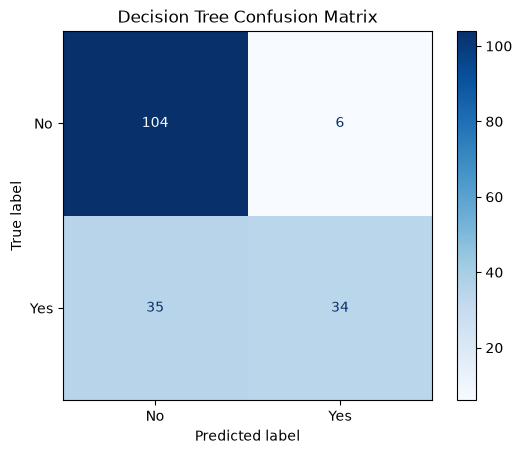


KNN Confusion Matrix:
[[95 15]
 [18 51]]


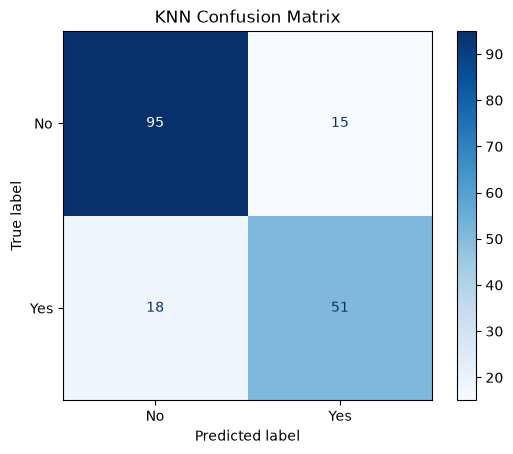


Naive Bayes Confusion Matrix:
[[93 17]
 [21 48]]


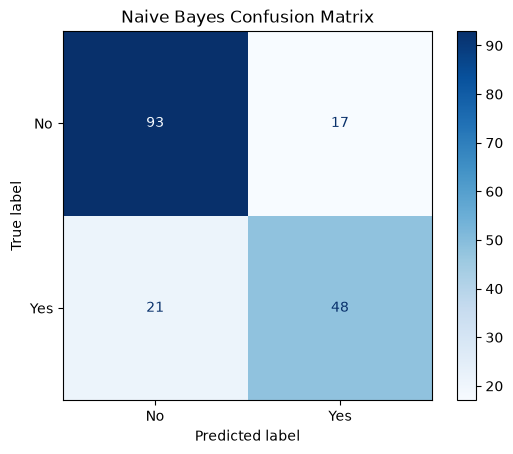

In [7]:

for name, pred in predictions.items():
    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    results.append([name, accuracy, precision, recall, f1])

    print("\n" + name + " Confusion Matrix:")
    print(confusion_matrix(y_test, pred))

    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No", "Yes"], cmap="Blues")
    plt.title(name + " Confusion Matrix")
    plt.show()


In [8]:

comparison = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1"])
print("\nComparison Table:")
print(comparison.round(3).to_string(index=False))

best = comparison.sort_values(by="F1", ascending=False).iloc[0]
print("\nRecommended model based on F1-score:", best["Model"])



Comparison Table:
        Model  Accuracy  Precision  Recall    F1
Decision Tree     0.771      0.850   0.493 0.624
          KNN     0.816      0.773   0.739 0.756
  Naive Bayes     0.788      0.738   0.696 0.716

Recommended model based on F1-score: KNN
